### **비지도 학습 및 생성 모델의 핵심 알고리즘들을 MNIST 데이터셋으로 실습**
PCA(주성분 분석), 오토인코더(Autoencoder), 인자 분석(Factor Analysis), GAN(생성적 적대 신경망)

- PCA: 이미지를 10개 숫자로 압축  
- Autoencoder: 이미지를 32개 숫자로 압축 후 복원  
- Factor Analysis: 이미지의 숨겨진 원인 분석  
- GAN: 노이즈로부터 새로운 이미지를 창조  

In [1]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

In [2]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

**MNIST** 
- 0부터 9까지의 손글씨 숫자 이미지 데이터셋
- 구성: 28x28 픽셀 크기의 흑백 이미지로 구성되어 있으며, 딥러닝 입문 및 알고리즘 검증용으로 가장 널리 쓰이는 표준 데이터

# PCA (Principal Component Analysis)

In [3]:
# MNIST 데이터 로드 및 전처리

(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

- X_train.reshape(-1, 784): $28 \times 28$ 크기의 2차원 이미지를 PCA 입력에 맞게 길이가 $784$인 1차원 벡터로 평탄화(Flatten)
- / 255.0: 0 ~ 255 사이의 픽셀 값을 255로 나누어 0 ~ 1 사이로 정규화(Normalization)

In [4]:
# 데이터셋의 형태 확인
print(X_train.shape)
print(y_train.shape)

(60000, 784)
(60000,)


### PCA 모델 생성 및 학습

In [5]:
n_components = 10  # 주성분 개수 설정 (예시: 10개)
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_train)

In [12]:
# 변환된 데이터 확인
X_pca

array([[ 0.48601015,  1.22617358,  0.09613354, ...,  0.62666468,
        -1.4255491 ,  0.77814932],
       [ 3.96752304,  1.15630211, -2.33858651, ..., -0.41164546,
         0.15866321,  0.5920349 ],
       [-0.2033318 , -1.53793393,  0.73925392, ...,  1.44545833,
        -0.44920029, -0.70003194],
       ...,
       [-0.69824882, -0.62775769,  1.01024738, ..., -0.72479423,
        -0.34323273,  1.05143132],
       [ 0.51218067,  0.02192916, -2.01513205, ...,  0.55187754,
        -0.06468935, -0.3680065 ],
       [-0.68014099,  0.09693648, -2.18046625, ..., -0.60570746,
         0.34236721, -0.4736462 ]])

$28 \times 28 = 784$차원의 원본 이미지가 **10개의 숫자(주성분 좌표)** 로 압축된 결과

In [10]:
# 원본 데이터 확인
X_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

- X_pca: (60000, 10) - 주성분 분석으로 핵심 정보만 남긴 데이터.
- X_train: (60000, 784) - 픽셀 하나하나의 값이 모두 들어있는 원본 데이터.

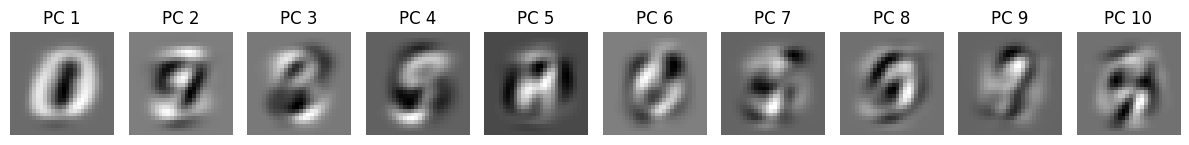

In [14]:
# 주성분(Principal Component) 벡터 시각화
 
principal_components = pca.components_ # 학습된 주성분 벡터(Eigenvectors)들 가져

plt.figure(figsize=(12, 3))
for i in range(n_components):
    plt.subplot(1, n_components, i + 1)
    principal_component = principal_components[i].reshape(28, 28) # 1차원 벡터(784,) 형태인 주성분을 시각화를 위해 다시 2차원 이미지(28, 28) 형태로 변환
    plt.imshow(principal_component, cmap='gray')
    plt.title(f"PC {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

- fetch_openml('mnist_784', version=1, as_frame=False): Scikit-Learn에서 MNIST 데이터셋을 다운로드하는 함수
- PCA(n_components=n_components): PCA 모델을 생성. n_components 는 유지할 주성분의 개수
- fit_transform(X_normalized): 데이터에 PCA를 적용하고, 주성분으로 이루어진 새로운 데이터셋을 반환
- components_: 학습된 주성분 벡터를 담고 있고, 각 벡터는 원본 데이터의 특성 수와 같은 차원을 가짐
- reshape(28, 28): (784,) 형태의 주성분 벡터를 (28, 28) 형태의 이미지로 변환
- imshow(..., cmap='gray'): 이미지를 흑백으로 시각화
- inverse_transform(): PCA를 통해 축소된 데이터를 다시 원본 차원으로 복원, 이 과정에서 정보 손실이 발생

# 오토인코더 (Autoencoder)
사용: 차원 축소, 노이즈 제거, 이상 탐지, 데이터 생성, 특징 추출

**오토인코더** 입력 데이터를 압축(Encoding)했다가 다시 원래대로 복원(Decoding)하는 비지도 학습 신경망

구조: 입력 -> 인코더 -> 잠재 벡터(Latent Vector) -> 디코더 -> 출력(복원된 입력)

- 앞서 배운 PCA가 '선형'적인 차원 축소라면, 오토인코더는 활성화 함수(ReLU 등)를 사용하여 데이터의 '비선형'적인 특징까지 학습할 수 있는 딥러닝 버전의 PCA라고 볼 수 있습니다.

In [15]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [17]:
# 하이퍼파라미터 설정
batch_size = 64
learning_rate = 0.001
num_epochs = 10
latent_dim = 32  # 잠재 공간의 차원: 784개의 픽셀 정보를 32개의 숫자로 요약

In [20]:
# 이미지 형태를 (batch_size, 28*28)로 변경
X_train = X_train.reshape((len(X_train), np.prod(X_train.shape[1:]))) 
# np.prod(X_train.shape[1:]) -> 데이터의 형태(Shape)에서 첫 번째 차원(데이터 개수)을 제외한 나머지 차원들의 곱을 계산
X_test = X_test.reshape((len(X_test), np.prod(X_test.shape[1:])))

In [21]:
print(X_train.shape)
print(X_test.shape)

(60000, 784)
(10000, 784)


X_train = X_train.reshape(-1, 784) ~ X_train = X_train.reshape((len(X_train), np.prod(X_train.shape[1:]))) 차이가 있나?

**결과적으로 차이는 없음**. 둘 다 (60000, 784) 형태로 변환

- np.prod(...) 사용: 이미지 크기가 변해도(예: 32x32) 자동으로 계산해주므로 범용적
- (-1, 784) 사용: 784를 직접 적었으므로 코드가 직관적이고 짧지만, 이미지 크기가 바뀌면 코드를 수정해야 함

In [23]:
# 인코더 정의 (Sequential 모델)
encoder = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(latent_dim) # latent_dim = 32
], name='encoder')

- 시퀀셜 구조로 구성된 인코더 모델 정의
- 784차원 입력 벡터 선언
- 784 → 128 차원 축소를 수행하는 첫 번째 은닉층
- 비선형성을 추가하는 ReLU 활성화 적용
- 128 → 64 차원 추가 축소를 수행하는 두 번째 은닉층
- latent_dim(32) 차원 잠재 벡터 생성층

In [24]:
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │           2,080 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# 디코더 정의 (Sequential 모델)
decoder = keras.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(784, activation='sigmoid') 
    # 시그모이드 함수는 출력값을 0과 1 사이로 만들어 줌. 우리가 맨 처음에 데이터를 0~1로 정규화했기 때문에, 모델의 출력도 이 범위에 맞추기 위해 사용
], name='decoder')

**대칭 구조 (Symmetric Structure)**
구조: 오토인코더는 인코더와 디코더가 거울 대칭적으로 구성. 

(784 $\rightarrow$ 128 $\rightarrow$ 64 $\rightarrow$ 32 $\rightarrow$ 64 $\rightarrow$ 128 $\rightarrow$ 784)

In [27]:
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

encoder - Total params: 110,816 & decoder ≠ Total params: 111,568 ?

**구조는 대칭인데 파라미터 수가 다른 이유는 편향(Bias) 때문**
- 인코더 편향 총합: $128 + 64 + 32 = \mathbf{224}$개
- 디코더 편향 총합: $64 + 128 + 784 = \mathbf{976}$개

  차이: $976 - 224 = \mathbf{752}$개

총 파라미터 차이를 계산해보면: $$111,568 (\text{디코더}) - 110,816 (\text{인코더}) = \mathbf{752}$$

### 오토인코더 전체 모델 정의

In [29]:
input_img = keras.Input(shape=(784,))
encoded = encoder(input_img)
decoded = decoder(encoded)
autoencoder = keras.Model(input_img, decoded, name='autoencoder')

In [30]:
# 모델 구조 확인
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ encoder (Sequential)                 │ (None, 32)                  │         110,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder (Sequential)                 │ (None, 784)                 │         111,568 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

**구조:** Input $\rightarrow$ encoder (모델) $\rightarrow$ decoder (모델) $\rightarrow$ Output

In [32]:
# 모델 컴파일
autoencoder.compile(optimizer='adam', loss='mse') 
# loss='mse'? -> 오토인코더 목표: 입력 이미지와 출력 이미지의 픽셀 값 차이를 줄이는 것

In [33]:
# 모델 학습
history = autoencoder.fit(X_train, X_train,
                          epochs=num_epochs,
                          batch_size=batch_size,
                          shuffle=True, # 매 에포크마다 데이터를 섞어서 모델이 데이터의 순서를 외우는 것을 방지
                          validation_data=(X_test, X_test))

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0568 - val_loss: 0.0200
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0186 - val_loss: 0.0145
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0142 - val_loss: 0.0123
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0122 - val_loss: 0.0109
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0109 - val_loss: 0.0101
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0102 - val_loss: 0.0095
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0094 - val_loss: 0.0087
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0089 - val_loss: 0.0084
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0084 - val_loss: 0.0080
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0081 - val_loss: 0.0076


**X_train, X_train:** 일반적인 학습(X, y)과 달리, 오토인코더는 입력 데이터(X)를 정답(Target)으로 그대로 사용. 즉, "입력된 이미지를 그대로 흉내 내라"는 명령
**validation_data=(X_test, X_test):** 학습에 참여하지 않은 테스트 데이터로 모델의 성능(얼마나 잘 복원하는지)을 검증. 역시 입력과 정답이 동일

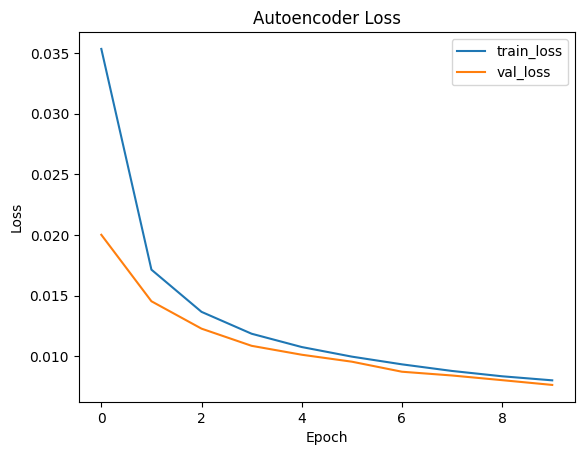

In [34]:
# 학습 손실 시각화  
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Autoencoder Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### 이미지 재구성 (Prediction)

In [35]:
# 학습된 모델로 이미지 생성 (테스트 데이터셋에서 일부 이미지 선택하여 재구성)
n = 10  # 처음 10개 이미지 시각화
plt.figure(figsize=(10, 4))
decoded_imgs = autoencoder.predict(X_test[:n]) 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


<Figure size 1000x400 with 0 Axes>

모델 내부적으로 [압축(인코더) $\rightarrow$ 복원(디코더)] 과정을 거친 후, 재구성된 이미지 결과(decoded_imgs)를 반환

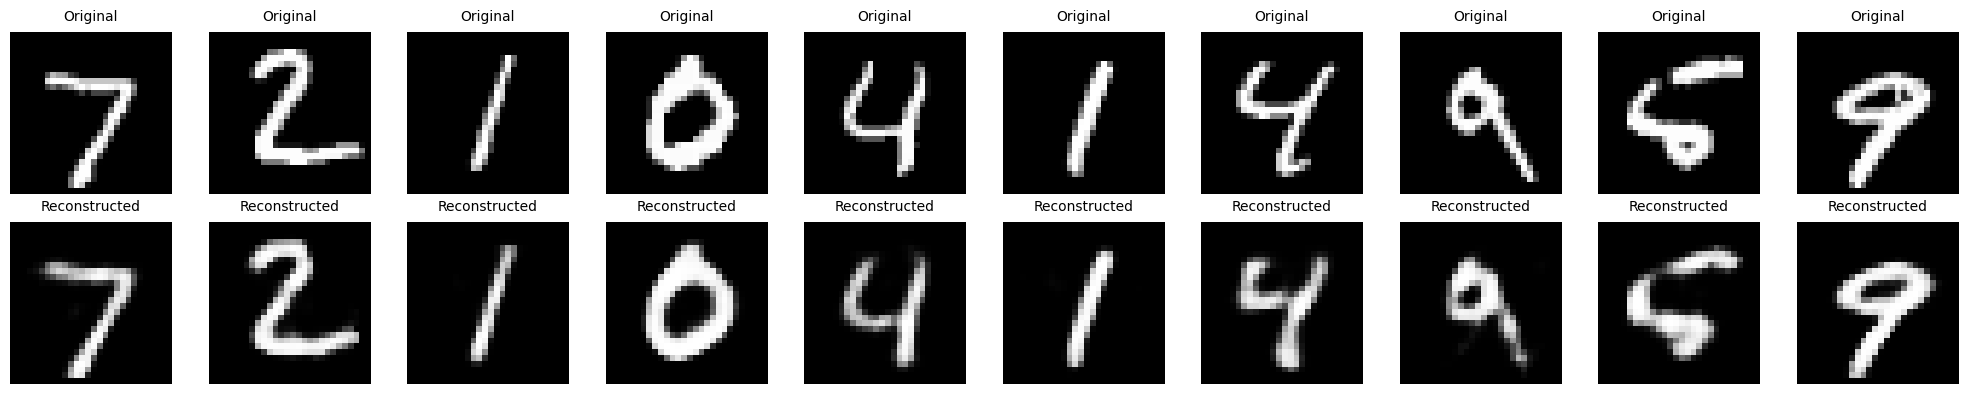

In [37]:
# 원본 vs 재구성 이미지 시각화
plt.figure(figsize=(2*n, 4))   

for i in range(n):
    # 원본 이미지
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original", fontsize=10, pad=8)   
    plt.axis('off')

    # 재구성된 이미지
    ax = plt.subplot(2, n, n + i + 1)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed", fontsize=10, pad=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

**손실 압축 (Lossy Compression):** 출력된 결과물을 보면 원본 숫자의 형태는 유지하고 있지만, 가장자리나 디테일이 약간 흐릿(Blurry)해진 것을 볼 수 있음
**원인:** 784개의 픽셀 정보를 32개라는 매우 작은 공간에 억지로 구겨 넣었기 때문에, 복원 과정에서 미세한 정보가 사라진 것. 

하지만 숫자가 무엇인지는 명확히 식별 가능하므로, 모델이 데이터의 핵심 특징(Manifold)을 잘 학습했음을 알 수 있음

# 인자 분석(Factor Analysis)
인자 분석은 변수들(픽셀들) 간의 상관관계(공분산)를 설명하는 숨겨진 요인(잠재 인자)을 찾는 기법

In [38]:
from sklearn.decomposition import FactorAnalysis

In [39]:
# 인자 분석 모델 생성 및 학습

n_components = 10  # 잠재 인자 개수 (10개)
fa = FactorAnalysis(n_components=n_components, random_state=42)
X_fa = fa.fit_transform(X_train)  # 학습 및 변환

In [40]:
# 잠재 인자로부터 이미지 생성 시도 (시각화)
mean_image = np.mean(X_train, axis=0) # 데이터의 평균값 (기본 배경)
components = fa.components_           # 학습된 인자 가중치 (Factor Loading)

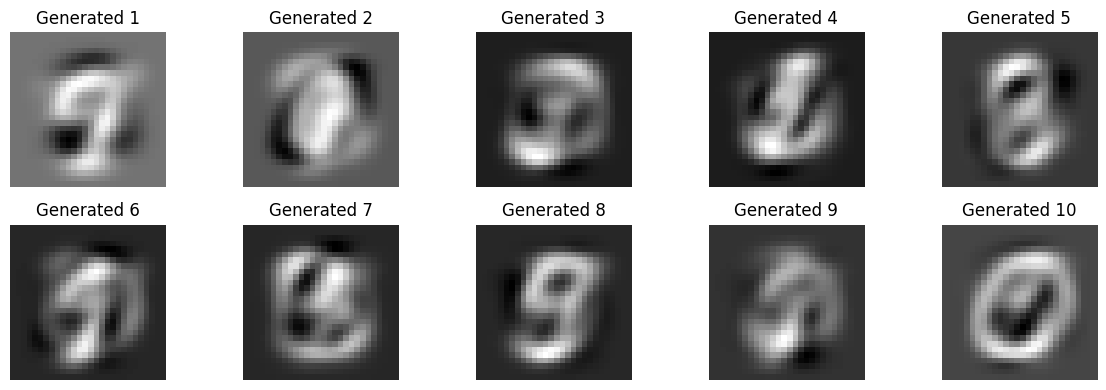

In [42]:
n_generated = 10
plt.figure(figsize=(12, 4))

for i in range(n_generated):
    # 각 잠재 인자에 랜덤한 가중치(Noise)를 주어 섞음
    random_factors = np.random.normal(size=n_components)
    
    # 생성 수식: 평균 이미지 + (랜덤 가중치 * 인자 벡터)
    generated_image = mean_image + np.dot(random_factors, components)
    generated_image = generated_image.reshape(28, 28)

    # 시각화
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_image, cmap='gray')
    plt.title(f"Generated {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

**생성 이미지** = 평균 이미지 + (임의 요인값 × 요인 가중치) → “요인 구조만 반영한 가상의 이미지”

# GAN(Generative Adversarial Network)
GAN은 가짜 데이터를 만들어내는 생성자(Generator)와
그 가짜가 진짜인지 판별하는 판별자(Discriminator)가
서로 경쟁하면서 함께 학습되어
결국 “진짜 같은 가짜 데이터를 만들어내는 모델”이다.

In [50]:
# 하이퍼파라미터 설정
batch_size = 64 # 한 번 학습에 쓰는 이미지 묶음 크기
learning_rate = 0.0002 # 안정적 GAN 학습을 위한 낮은 학습률
num_epochs = 50 # 전체 데이터를 50번 반복 학습
latent_dim = 100 # 생성자에 넣는 랜덤 잡음 벡터 크기
num_channels = 1 # MNIST가 흑백 이미지라 채널 1
img_height = 28
img_width = 28

In [51]:
# MNIST 데이터 로드 및 전처리
(train_images, _), (_, _) = keras.datasets.mnist.load_data()
train_images = train_images.reshape(train_images.shape[0], img_height, img_width, num_channels).astype('float32')

# 이미지를 -1과 1 사이로 정규화
train_images = (train_images - 127.5) / 127.5

- _ (언더바)를 사용하여 레이블(y)과 테스트 데이터(X_test)를 버림
- GAN은 이미지가 0인지 1인지 맞추는 게 아니라, 이미지 자체를 만들어내는 것이 목표이므로 정답 라벨이 필요 없음. 학습 데이터(train_images)만 사용

In [52]:
# 데이터셋 생성
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(buffer_size=60000).batch(batch_size)

In [53]:
# 생성자(Generator) 모델 정의
def make_generator_model():
    model = keras.Sequential([
        # 입력(잡음) -> 기초 이미지 특징 생성
        layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(latent_dim,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        # 1차원 벡터를 3차원 텐서로 변환
        layers.Reshape((7, 7, 256)),

        # 업샘플링 (이미지 크기 키우기): 7x7 -> 7x7
        layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        # 업샘플링: 7x7 -> 14x14
        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        # 업샘플링: 14x14 -> 28x28 (최종 출력)
        layers.Conv2DTranspose(num_channels, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
    ])
    return model

### Generator 모델 정의 — 라인별 요약 + 옵션 의미

1. layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(latent_dim,))
   - 요약: latent 벡터를 7×7×256 차원의 큰 feature 벡터로 변환하는 Dense 층
   - 옵션:
     - units=7*7*256: 출력 뉴런 수
     - use_bias=False: BatchNorm을 사용하므로 bias 비활성화
     - input_shape=(latent_dim,): 입력 잡음 벡터 크기

2. layers.BatchNormalization()
   - 요약: Dense 출력값을 정규화하여 학습 안정화
   - 옵션 없음: 기본 모멘텀/epsilon 사용

3. layers.LeakyReLU()
   - 요약: 음수 영역에서도 작은 기울기를 주는 활성화 함수
   - 옵션 (기본): alpha=0.3 → 음수 기울기 크기

4. layers.Reshape((7, 7, 256))
   - 요약: 1D 벡터를 7×7×256 텐서(이미지 형태)로 변환
   - 옵션:
     - target_shape=(7,7,256): 출력 텐서 구조

5. layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False)
   - 요약: 7×7 크기를 유지하며 채널을 128로 줄이는 upsampling 성질의 ConvTranspose
   - 옵션:
     - filters=128: 출력 채널 수
     - kernel_size=(5,5): 필터 크기
     - strides=(1,1): 공간 크기 그대로 유지
     - padding='same': 입력 크기 유지
     - use_bias=False: BatchNorm 때문에 bias 제거

6. layers.BatchNormalization()
   - 요약: ConvTranspose 출력값 정규화하여 안정적 학습 유도

7. layers.LeakyReLU()
   - 요약: 비선형성 추가, generator가 더 복잡한 패턴 생성 가능하게 함

8. layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False)
   - 요약: 해상도 2배 확대 (7×7 → 14×14) & 채널을 64로 축소
   - 옵션:
     - strides=(2,2): upsampling 발생
     - filters=64: 출력 채널 수

9. layers.BatchNormalization()
   - 요약: 업샘플링된 feature map을 정규화

10. layers.LeakyReLU()
    - 요약: 활성화 추가

11. layers.Conv2DTranspose(num_channels, (5, 5), strides=(2, 2),
                          padding='same', use_bias=False, activation='tanh')
    - 요약: 최종 28×28 해상도 생성 & 출력 채널 생성 (MNIST=1)
    - 옵션:
      - filters=num_channels: 이미지 채널 (1=흑백, 3=RGB)
      - strides=(2,2): 14×14 → 28×28 업샘플링
      - activation='tanh': 출력 범위를 [-1, 1]로 제한 (GAN 기본 규칙)


In [54]:
# 생성자 모델 객체 생성
generator = make_generator_model()

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [55]:
# 판별자(Discriminator) 모델 정의
def make_discriminator_model():
    model = keras.Sequential([
        # 입력 이미지(28x28) -> 특징 추출 및 다운샘플링 (14x14)
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=(img_height, img_width, num_channels)),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        # 특징 추출 및 다운샘플링 (7x7)
        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        # 1차원으로 펼치기 및 판별값 출력
        layers.Flatten(),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

discriminator = make_discriminator_model()

C:\Users\dadab\miniconda3\envs\deeplearning\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Discriminator 모델 정의 — 라인별 요약 + 옵션 의미

1. layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same',
                 input_shape=(img_height, img_width, num_channels))
   - 요약: 28×28 입력 이미지를 14×14로 다운샘플링하며 특징(엣지/패턴) 추출
   - 옵션:
     - filters=64: 출력 채널 수
     - kernel_size=(5,5): 필터 크기
     - strides=(2,2): 해상도 절반(28→14)으로 축소
     - padding='same': 공간 크기 유지하며 컨볼루션
     - input_shape: 입력 이미지 크기(MNIST: 28×28×1)

2. layers.LeakyReLU()
   - 요약: 음수에서도 작게 흐르는 기울기 제공(기본 alpha=0.3)
   - GAN에서 D/G 모두 안정적 학습을 위해 거의 필수

3. layers.Dropout(0.3)
   - 요약: 30%를 무작위로 비활성화하여 과적합 방지 & 일반화 향상
   - 옵션: rate=0.3 → 드롭 비율 30%

4. layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same')
   - 요약: 두 번째 다운샘플링 (14×14 → 7×7) + 더 깊은 특징 추출
   - 옵션:
     - filters=128: 더 많은 특징 채널
     - strides=(2,2): 해상도 반으로 축소
     - padding='same': 동일한 크기 유지하며 처리

5. layers.LeakyReLU()
   - 요약: 비선형성 제공, 판별 능력 강화

6. layers.Dropout(0.3)
   - 요약: 과적합 방지 및 GAN D의 지나친 강함 억제(모델 collapse 방지)

7. layers.Flatten()
   - 요약: 7×7×128 특징 맵을 1차원 벡터로 변환
   - 의미: Dense 층으로 연결하기 위한 준비

8. layers.Dense(1, activation='sigmoid')
   - 요약: 입력 이미지가 진짜(1)인지 가짜(0)인지 확률을 출력하는 최종 판별층
   - 옵션:
     - units=1: 이진 판별
     - activation='sigmoid': 확률값 (0~1) 출력

### 최종 모델 생성
discriminator = make_discriminator_model()

### 손실 함수(Loss Function) 정의

In [56]:
# 손실 함수 및 옵티마이저 정의
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

### 최적화 도구 및 학습 단계 정의

In [59]:
# 일반적인 모델과 달리 GAN은 두 개의 네트워크가 따로 존재하므로, 최적화 도구(관리자)도 2개가 필요
generator_optimizer = tf.keras.optimizers.Adam(learning_rate)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate)

# 학습 루프 정의
@tf.function
def train_step(images):
    noise = tf.random.normal([batch_size, latent_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

In [61]:
# 전체 학습 루프 정의
def train(dataset, epochs):
    for epoch in range(epochs):
        gen_loss_avg = tf.keras.metrics.Mean()
        disc_loss_avg = tf.keras.metrics.Mean()

        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
            gen_loss_avg(gen_loss)
            disc_loss_avg(disc_loss)

        print(f'Epoch {epoch + 1}, Generator Loss: {gen_loss_avg.result():.4f}, Discriminator Loss: {disc_loss_avg.result():.4f}')
        generate_and_save_images(generator, epoch + 1, seed) # 실제 생성 이미지를 직접 확인

    generate_and_save_images(generator, epochs, seed)

GAN은 생성자와 판별자가 서로 경쟁하기 때문에 Loss가 안정적으로 감소하지 않고 진동하는 것이 정상이며, 단순한 숫자로 성능을 판단하기 어렵다. 따라서 학습 중간마다 실제 생성 이미지를 직접 확인하는 과정이 필수적이다

In [62]:
# 생성된 이미지 시각화 함수 정의
def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)

    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow((predictions[i, :, :, 0] * 127.5 + 127.5).numpy().astype('uint8'), cmap='gray')
        plt.axis('off')

    plt.suptitle(f'Generated Images Epoch {epoch}')
    plt.savefig('image_at_epoch_{:04d}.png'.format(epoch))
    plt.show()

**역정규화(Denormalization) 과정**

모델의 출력(tanh)은 -1 ~ 1 사이의 값입니다. 이를 화면에 표시하기 위해 다시 0 ~ 255 범위로 되돌림.
- 계산: $(-1 \times 127.5) + 127.5 = 0$, $(1 \times 127.5) + 127.5 = 255$

In [63]:
# 학습에 사용할 시드 벡터
seed = tf.random.normal([16, latent_dim])

Epoch 1, Generator Loss: 1.3294, Discriminator Loss: 0.9627


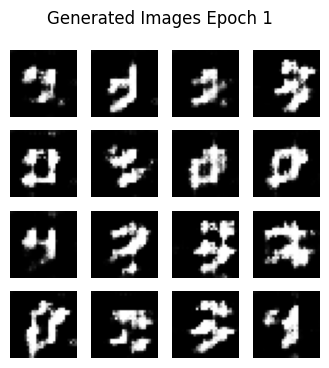

Epoch 2, Generator Loss: 1.2597, Discriminator Loss: 1.0679


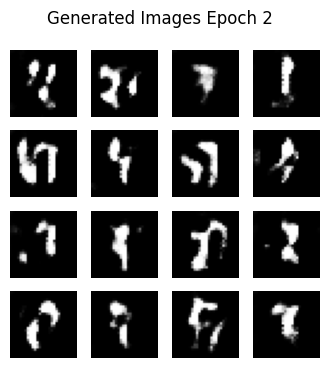

Epoch 3, Generator Loss: 1.3953, Discriminator Loss: 0.9997


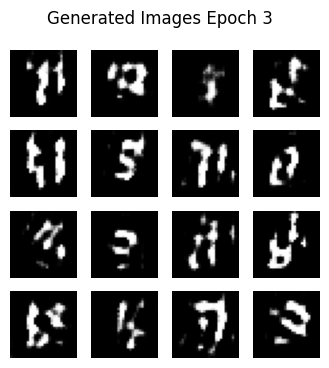

Epoch 4, Generator Loss: 1.3485, Discriminator Loss: 1.0160


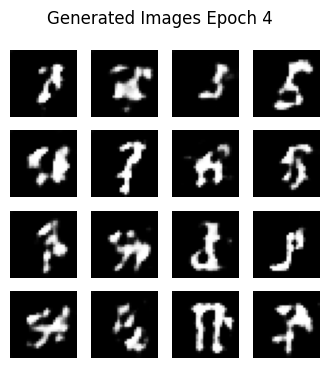

Epoch 5, Generator Loss: 1.4699, Discriminator Loss: 0.9543


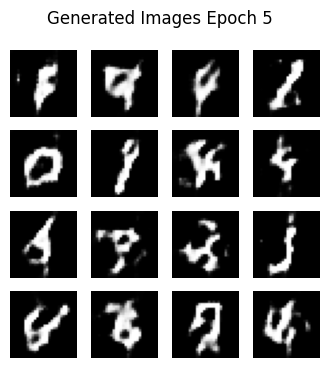

Epoch 6, Generator Loss: 1.4696, Discriminator Loss: 0.9771


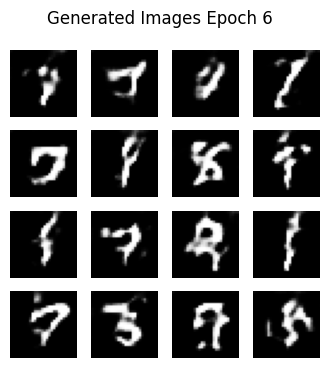

Epoch 7, Generator Loss: 1.3604, Discriminator Loss: 1.0361


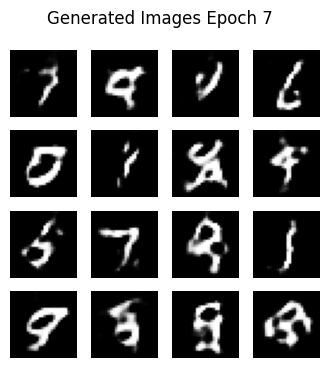

Epoch 8, Generator Loss: 1.2167, Discriminator Loss: 1.1076


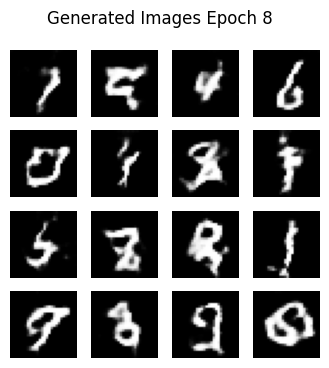

Epoch 9, Generator Loss: 1.2264, Discriminator Loss: 1.1231


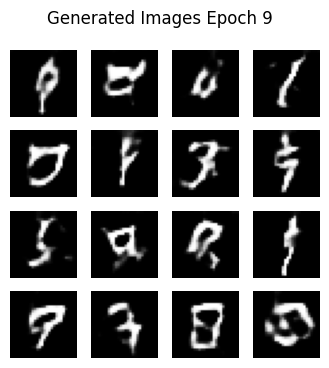

Epoch 10, Generator Loss: 1.0717, Discriminator Loss: 1.1770


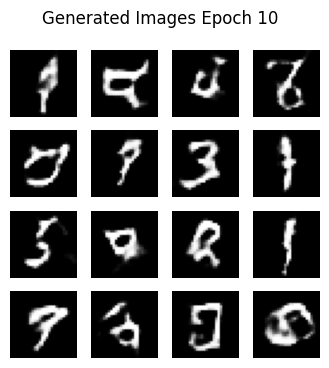

Epoch 11, Generator Loss: 1.1336, Discriminator Loss: 1.1616


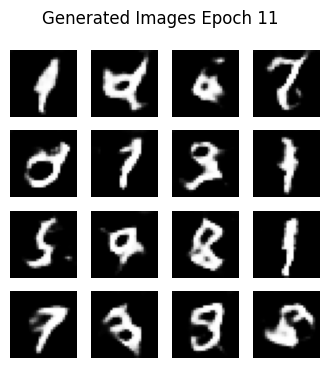

Epoch 12, Generator Loss: 1.0569, Discriminator Loss: 1.1795


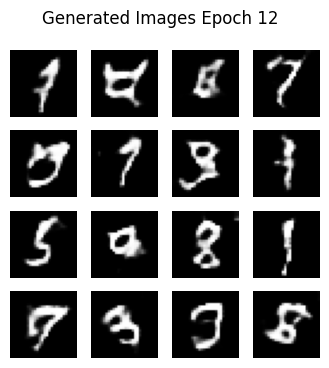

Epoch 13, Generator Loss: 1.0425, Discriminator Loss: 1.1854


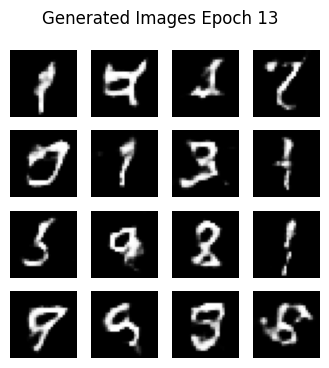

Epoch 14, Generator Loss: 1.0509, Discriminator Loss: 1.1878


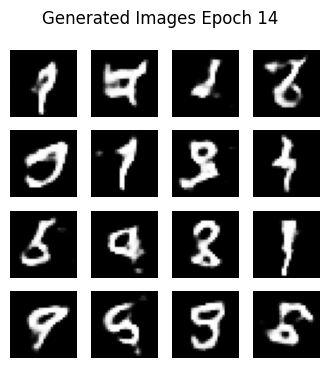

Epoch 15, Generator Loss: 1.0641, Discriminator Loss: 1.1837


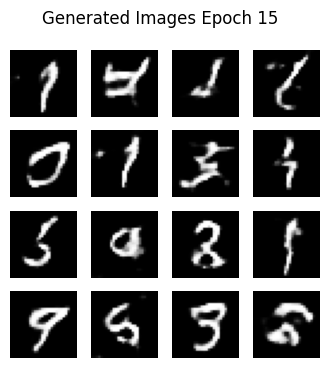

Epoch 16, Generator Loss: 1.0346, Discriminator Loss: 1.1887


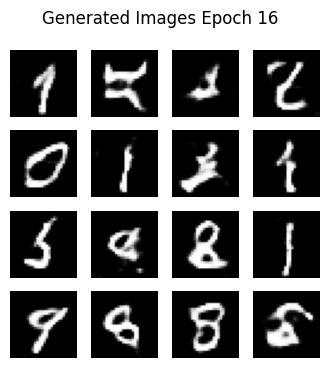

Epoch 17, Generator Loss: 1.0420, Discriminator Loss: 1.1898


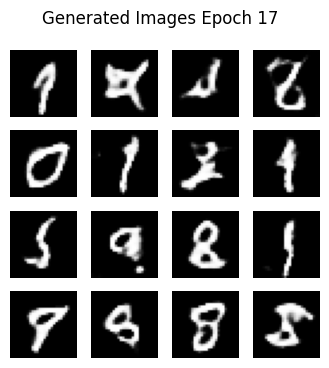

Epoch 18, Generator Loss: 1.0363, Discriminator Loss: 1.1935


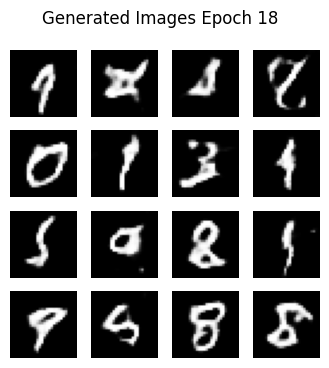

Epoch 19, Generator Loss: 1.0255, Discriminator Loss: 1.1940


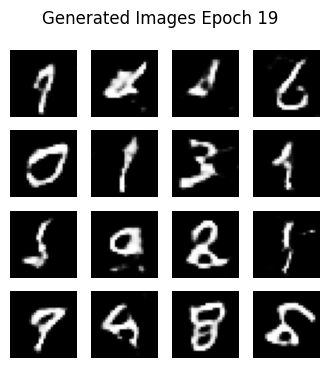

Epoch 20, Generator Loss: 1.0335, Discriminator Loss: 1.1937


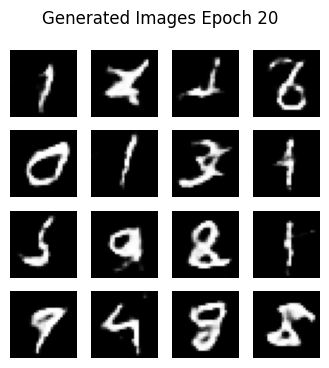

Epoch 21, Generator Loss: 0.9971, Discriminator Loss: 1.2084


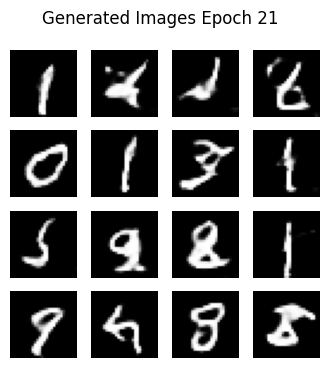

Epoch 22, Generator Loss: 1.0688, Discriminator Loss: 1.1927


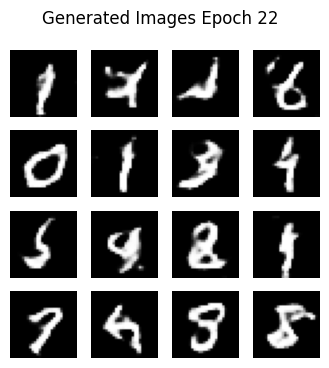

Epoch 23, Generator Loss: 1.0100, Discriminator Loss: 1.1959


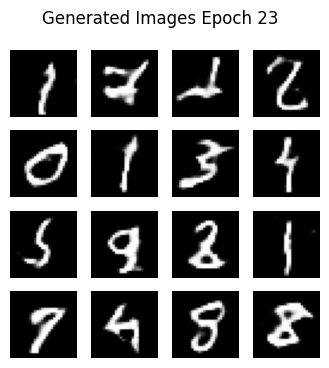

Epoch 24, Generator Loss: 0.9995, Discriminator Loss: 1.2079


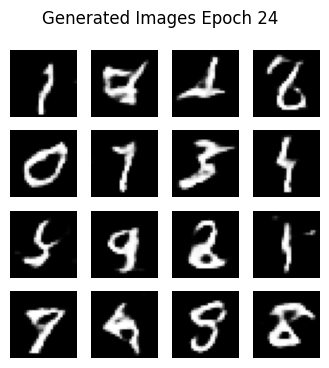

Epoch 25, Generator Loss: 1.0419, Discriminator Loss: 1.1990


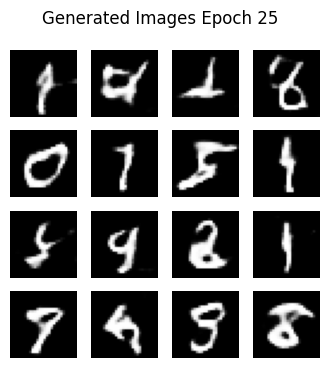

Epoch 26, Generator Loss: 1.0007, Discriminator Loss: 1.2063


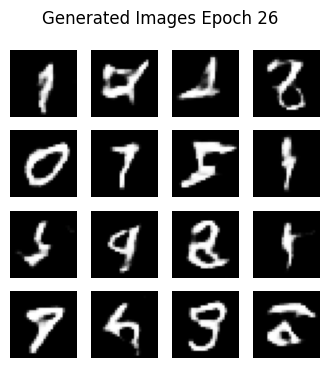

Epoch 27, Generator Loss: 1.0083, Discriminator Loss: 1.2061


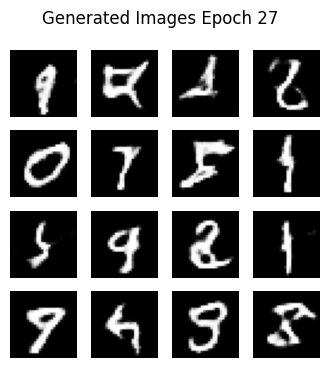

Epoch 28, Generator Loss: 1.0499, Discriminator Loss: 1.1988


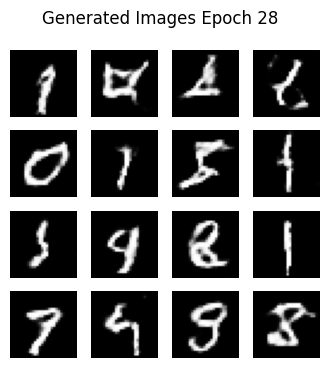

Epoch 29, Generator Loss: 1.0035, Discriminator Loss: 1.2013


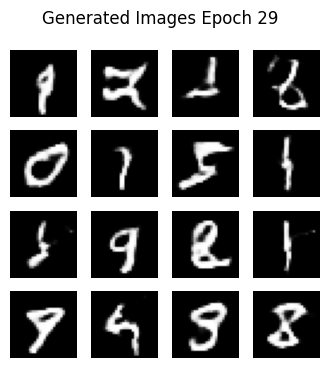

Epoch 30, Generator Loss: 1.0017, Discriminator Loss: 1.2035


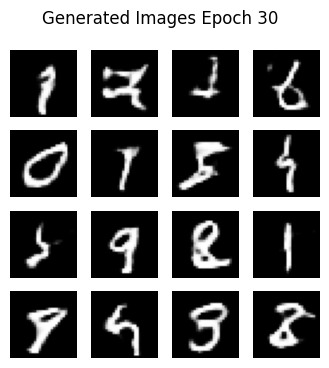

Epoch 31, Generator Loss: 1.0326, Discriminator Loss: 1.2067


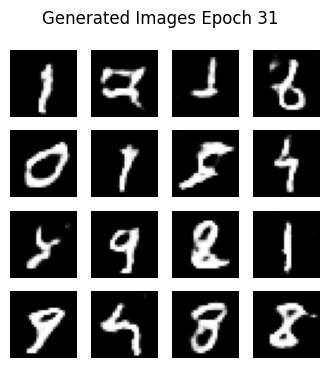

Epoch 32, Generator Loss: 1.0150, Discriminator Loss: 1.2071


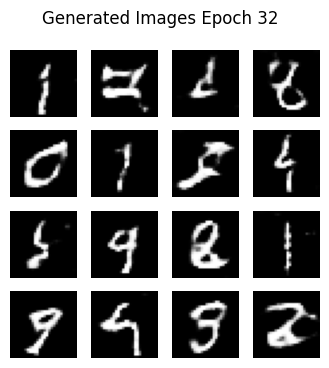

Epoch 33, Generator Loss: 0.9995, Discriminator Loss: 1.2092


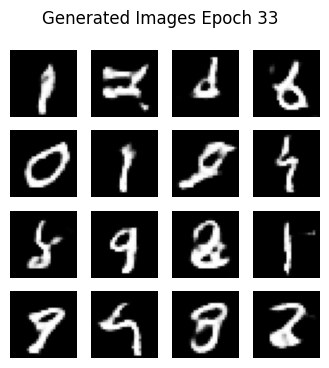

Epoch 34, Generator Loss: 1.0330, Discriminator Loss: 1.2095


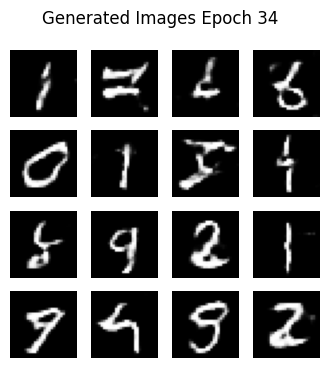

Epoch 35, Generator Loss: 0.9954, Discriminator Loss: 1.2135


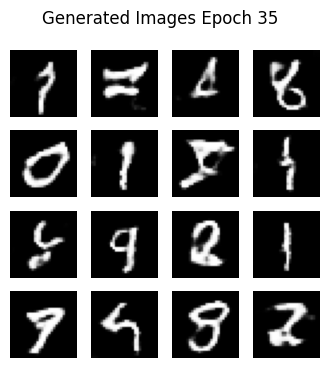

Epoch 36, Generator Loss: 0.9833, Discriminator Loss: 1.2149


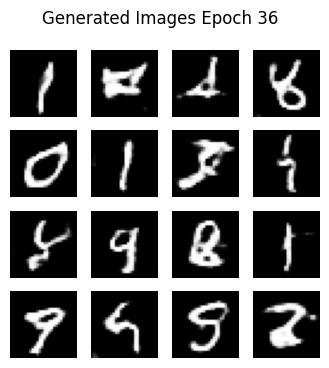

Epoch 37, Generator Loss: 1.0495, Discriminator Loss: 1.2065


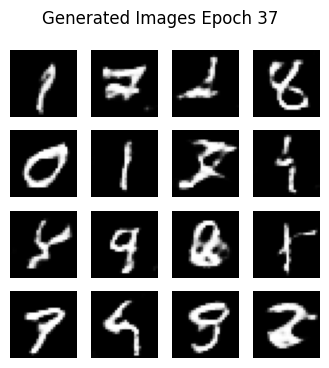

Epoch 38, Generator Loss: 0.9911, Discriminator Loss: 1.2132


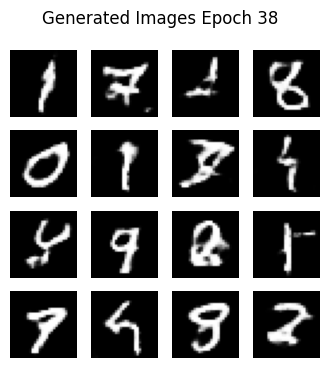

Epoch 39, Generator Loss: 0.9785, Discriminator Loss: 1.2210


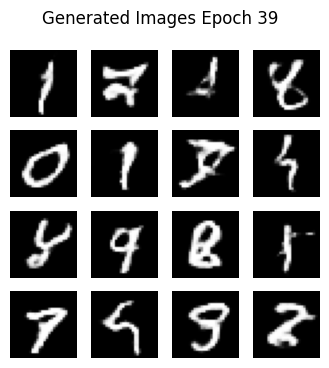

Epoch 40, Generator Loss: 0.9955, Discriminator Loss: 1.2203


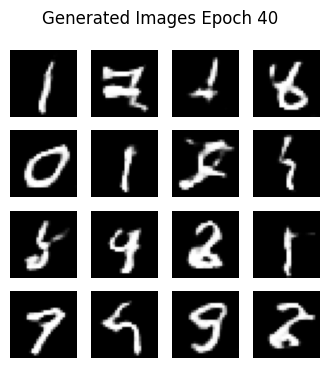

Epoch 41, Generator Loss: 0.9927, Discriminator Loss: 1.2215


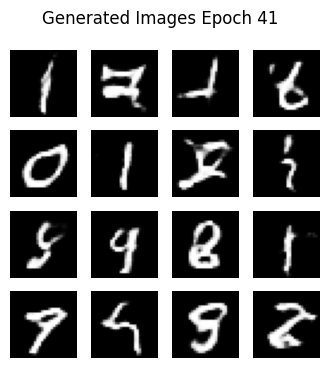

Epoch 42, Generator Loss: 0.9743, Discriminator Loss: 1.2279


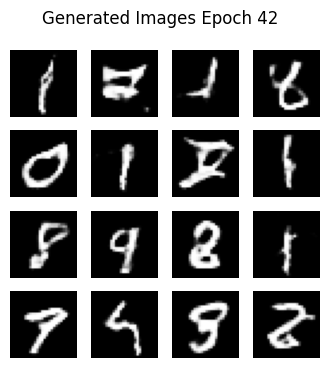

Epoch 43, Generator Loss: 1.0442, Discriminator Loss: 1.2178


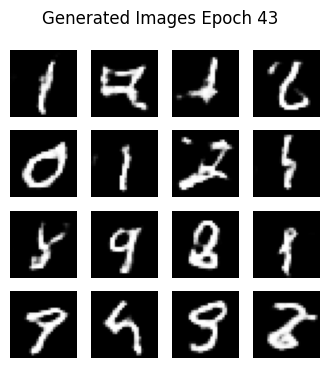

Epoch 44, Generator Loss: 0.9869, Discriminator Loss: 1.2208


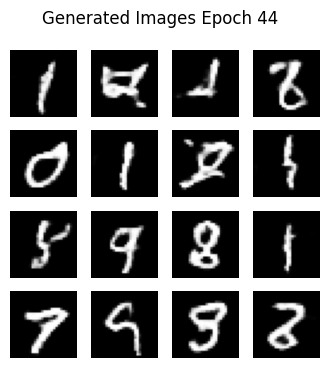

Epoch 45, Generator Loss: 0.9727, Discriminator Loss: 1.2278


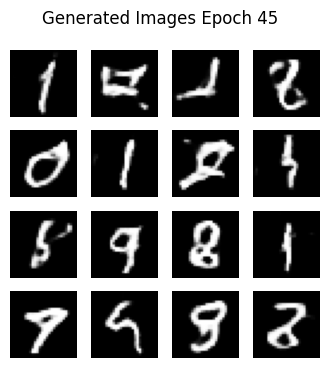

Epoch 46, Generator Loss: 0.9831, Discriminator Loss: 1.2278


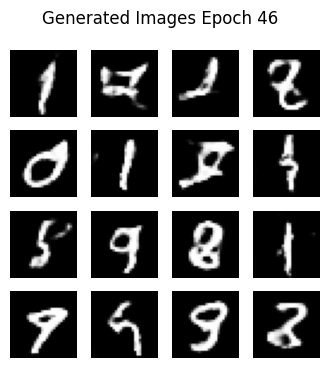

Epoch 47, Generator Loss: 0.9796, Discriminator Loss: 1.2312


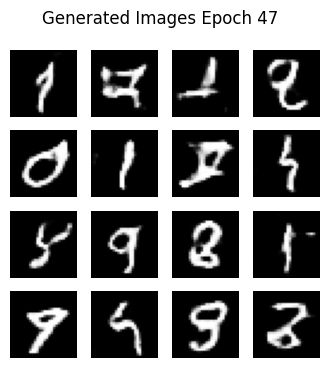

Epoch 48, Generator Loss: 0.9712, Discriminator Loss: 1.2339


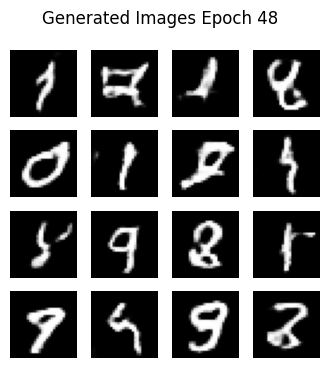

Epoch 49, Generator Loss: 0.9878, Discriminator Loss: 1.2316


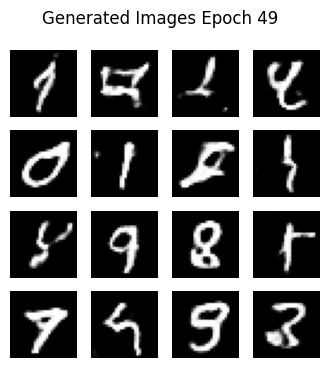

Epoch 50, Generator Loss: 0.9621, Discriminator Loss: 1.2414


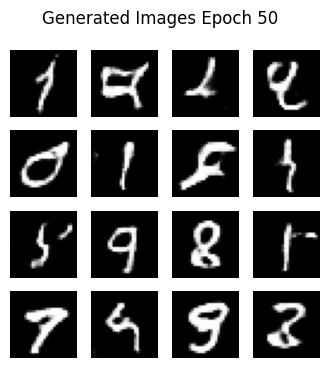

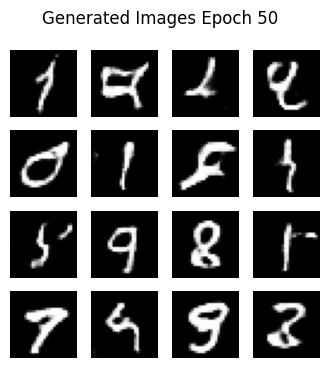

In [64]:
# 모델 학습 시작
train(train_dataset, num_epochs)